# MTM field widths: GS2 $\phi$ and $A_\parallel$ equivalent Gaussian widths in $\theta_b$, width laws, predicted GFTM settings

Fusion_PhD-bhx7.17. The user (2026-11-17): use the extent-to-width transformation to get the width of each GS2 MTM's $\phi$ and
$A_\parallel$ separately, look at their distributions, fit width laws, and ask whether one set of GFTM settings can resolve both.

**The conversion is analytic, in the basis coordinate.** TGLF and GFTM expand each field in $\psi_n(x)\propto H_n(x)e^{-x^2/2}$ with
$x=\theta_b/\mathrm{WIDTH}$, where $\theta_b=2\pi l_\parallel/L_{\rm turn}$ is the arc length along the field line, not $\theta$.
pyrokinetics now maps $\theta\to\theta_b$ exactly from each sample's geometry: `FieldLine.compute_basis_angle` (pyro PR #617, the
cumulative form of `compute_length_per_turn`). In $\theta_b$, the 95 % extent of $|f|^2$ (pyro `Extent`) is
- $E=2.772\,W$ for an even field, $|\psi_0|^2\propto e^{-x^2}$;
- $E=3.953\,W$ for an odd field, $|\psi_1|^2\propto x^2e^{-x^2}$.

An MTM has tearing parity: $A_\parallel$ even, $\phi$ odd. So $W_{A_\parallel}=E^{\theta_b}_{A_\parallel}/2.772$ and $W_\phi=E^{\theta_b}_\phi/3.953$.
No runs are calibrated against. The notebook checks the map against GFTM itself (NBASIS-2 eigenfunctions are pure Hermite functions
in $\theta_b$) and against qp5.49's run-calibrated KBM widths.

**Populations.** GS2 `pyro_cube_avg` of NSTX_MTM n1000 (fit) and n300 (out of sample), as the law2 refit (`mtm_extent_law_refit`):
label MTM ($T>0.15$, $\omega<0$), $\gamma>0$, `growth_rate_tolerance` $<0.01$. A field whose $|f|^2$ has more than 1 % beyond
$0.9\max|\theta|$ touches the box: its extent, and so its width, is a lower bound (right-censored).

In [1]:
import os
from multiprocessing import get_context
from pathlib import Path
import time
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator, StrMethodFormatter
from scipy import optimize, stats
from scipy.stats import chi2, norm
from pyrokinetics import Pyro, PyroHypercube
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.diagnostics.field_line import FieldLine
from general_analysis import mode_classification as mc

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
plt.rcParams["lines.marker"] = ""     # the style marks every line; reference lines (axvline/axhline) must not carry dots
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
data_root = Path(os.path.expandvars(os.environ["GK_DATA_ROOT"]))     # the WORK tree
plots_dir = ROOT / "Plots" / "mtm_field_widths"
plots_dir.mkdir(parents=True, exist_ok=True)
n_cpu = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))

draws = {"n1000": "beta_q_shat_ky_n1000", "n300": "beta_q_shat_ky_n300"}
arms = {"m11_new": "m11_new", "law2 rule": "extent_rule_tf035_law2", "law2 maxbasis": "extent_maxbasis_law2_s100", "fw174": "gftm_fw174"}
m11_width = 5.89285              # registry gftm_m11_new: FIND_WIDTH F, WIDTH 5.89285 (its cube does not record the width)
fields = ["phi", "apar"]
field_label = {"phi": r"$\phi$", "apar": r"$A_\parallel$"}
mtm_parity = {"phi": "odd", "apar": "even"}
kbm_parity = {"phi": "even", "apar": "odd"}
tolerance_gate, edge_gate = 1e-2, 1e-2
target_error = 0.03              # qp5.49: the extent-convergence criterion behaves like a Gaussian at 3 % relative L2 error
nbasis_cap, nxgrid_cap, nxgrid_floor = 59, 65, 14
kbm_cases = ["SPR-045", "M1", "R4", "R3"]
check_widths = [0.2, 0.4, 0.8, 1.6]
calibration_widths = [0.2, 0.2297, 0.2639, 0.3031, 0.3482, 0.4, 0.4595, 0.5279, 0.6063, 0.6965, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5,
                      1.6, 1.9218, 2.3083, 2.7726, 3.3302, 4.0]   # qp5.49's fixed-width GFTM NBASIS-2 ladder


def extent_95(power, coordinate):
    # pyro's 95 % Extent of |f|^2 over `coordinate` (theta or theta_b), finite points only
    keep = np.isfinite(power)
    return float(Extent._compute(xr.DataArray(power[keep][None], dims=("sample", "theta"), coords=dict(theta=coordinate[keep])), 0.95)[0][0])


def edge_fraction(power, theta):
    # share of |f|^2 beyond 0.9 of the run's own theta box (law2 refit's box-contact measure)
    keep = np.isfinite(power)
    power, theta = power[keep], theta[keep]
    return float(np.trapezoid(power * (abs(theta) > 0.9 * abs(theta).max()), theta) / np.trapezoid(power, theta))

## The analytic factors, and pyro's `Extent` on the models
qp5.43 (`basis_resolution_rule`) quoted $4.32\sigma$ for the odd model, measured with the `Extent` of that time. pyro's `Extent` is
now the central-95 % rule (2.5 % in each tail). On a fine grid it gives the $\chi^2_3$ quantile, $3.953$, for $x\,e^{-x^2/2}$; 4.32 is
not reproduced and is superseded.

In [2]:
analytic_factor = {"even": 2 * norm.ppf(0.975) / np.sqrt(2), "odd": 2 * np.sqrt(chi2.ppf(0.95, 3) / 2)}
x_fine = np.linspace(-12, 12, 200001)
model = {"even": lambda x: np.exp(-x ** 2 / 2), "odd": lambda x: x * np.exp(-x ** 2 / 2)}
for parity in model:
    measured = extent_95(model[parity](x_fine) ** 2, x_fine)
    assert abs(measured - analytic_factor[parity]) < 1e-3, (parity, measured)
    print(f"{parity}: pyro Extent {measured:.4f}, analytic {analytic_factor[parity]:.4f}")
assert abs(extent_95(model["odd"](x_fine) ** 2, x_fine) - 4.32) > 0.3

even: pyro Extent 2.7718, analytic 2.7718
odd: pyro Extent 3.9534, analytic 3.9534


## Check 1: the pyro map against GFTM itself
At NBASIS 2, GFTM's $\phi$ is $\psi_0$ and its $A_\parallel$ is $\psi_1$ (a KBM: ballooning parity). On $x=\theta_b/W$ they must be
$e^{-x^2/2}$ and $x\,e^{-x^2/2}$. Per sample, field and WIDTH: the relative $L^2$ residual of $|f|$ against the best multiple of
$|{\rm model}|$, with $x$ from $\theta_b$ (pyro map) and, for contrast, from $\theta$; and the extent in $\theta_b$ over $W$ against
the model's extent **on the same $\theta_b$ points** (GFTM writes only 289 points over $\pm9\pi$, so at small WIDTH the grid,
not the map, sets the extent's last digits). Samples: qp5.49's fixed-width leaves `galF_w*_nb2_nx32`, all four KBM databases.

In [3]:
def check_leaf(spec):
    case, width = spec
    leaf = (data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"galF_{f'w{width:.4f}'.replace('.', 'p')}_nb2_nx32")
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    output = scan.gk_output.data
    gamma = output.growth_rate.pint.dequantify()
    assert (gamma.fillna(-np.inf).argmax("mode") == 0).all()                      # IBRANCH -1: mode 0 is dominant
    rows = []
    for i, name in enumerate(output.sample_name.values):
        dominant = output.isel(sample=i, mode=0)  # mode0-guard-allow: argmax == 0 asserted above
        if not np.isfinite(float(gamma.isel(sample=i, mode=0))):  # mode0-guard-allow: argmax == 0 asserted above
            continue
        theta = output.theta.values
        basis_angle = FieldLine(scan.sample_pyro(i, gk_output=xr.Dataset())).compute_basis_angle(theta)
        for field, parity in kbm_parity.items():
            amplitude = np.abs(dominant[field].pint.dequantify().values.ravel())
            if not np.isfinite(amplitude).all() or amplitude.max() == 0:
                continue
            row = dict(case=case, sample=str(name), width=width, field=field)
            for coordinate_name, coordinate in (("theta_b", basis_angle), ("theta", theta)):
                shape = np.abs(model[parity](coordinate / width))
                weight = np.gradient(coordinate)
                scale = (amplitude * shape * weight).sum() / (shape ** 2 * weight).sum()
                row[f"residual_{coordinate_name}"] = np.sqrt(((amplitude - scale * shape) ** 2 * weight).sum() / (amplitude ** 2 * weight).sum())
            row["extent_over_width"] = extent_95(amplitude ** 2, basis_angle) / width
            row["model_extent_over_width"] = extent_95(model[parity](basis_angle / width) ** 2, basis_angle) / width
            row["extent_theta_over_width"] = extent_95(amplitude ** 2, theta) / width
            rows.append(row)
    return pd.DataFrame(rows)


with get_context("fork").Pool(n_cpu) as pool:
    code_check = pd.concat(pool.map(check_leaf, [(case, width) for case in kbm_cases for width in check_widths]), ignore_index=True)
code_check["extent_over_model"] = code_check.extent_over_width / code_check.model_extent_over_width
code_check_summary = code_check.groupby(["field", "width"]).agg(
    n=("sample", "size"), residual_theta_b_median=("residual_theta_b", "median"), residual_theta_b_q90=("residual_theta_b", lambda r: r.quantile(0.9)),
    residual_theta_median=("residual_theta", "median"), extent_over_model_median=("extent_over_model", "median"),
    extent_over_width_median=("extent_over_width", "median"), extent_theta_over_width_median=("extent_theta_over_width", "median"))
code_check_summary.to_csv(plots_dir / "code_check_summary.csv")
print(code_check_summary.round(4).to_string())
assert (code_check_summary.residual_theta_b_median < 0.02).all()
assert (abs(code_check_summary.extent_over_model_median - 1) < 0.02).all()

               n  residual_theta_b_median  residual_theta_b_q90  residual_theta_median  extent_over_model_median  extent_over_width_median  extent_theta_over_width_median
field width                                                                                                                                                               
apar  0.2    718                   0.0009                0.0017                 0.4883                    0.9992                    4.2215                          6.3814
      0.4    738                   0.0008                0.0013                 0.4378                    0.9996                    4.2352                          5.7919
      0.8    734                   0.0009                0.0025                 0.3112                    1.0004                    4.1338                          4.8591
      1.6    721                   0.0005                0.0020                 0.1577                    0.9998                    3.9727       

## Check 2: KBMs, analytic $\theta_b$ widths against qp5.49's run-calibrated widths
The 738 GS2-KBMs of the four `kbm_free` hypercubes. Analytic: $W_\phi=E^{\theta_b}_\phi/2.772$, $W_{A_\parallel}=E^{\theta_b}_{A_\parallel}/3.953$.
Run-calibrated (qp5.49, re-derived here): the WIDTH at which the NBASIS-2 GFTM extent in $\theta$ equals the GS2 extent in $\theta$,
interpolated in $\log$ over the 24 fixed widths, with $E(W)$ made non-decreasing and out-of-range targets censored.

In [4]:
def gftm_nb2_extents(spec):
    case, width = spec
    leaf = data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"galF_{f'w{width:.4f}'.replace('.', 'p')}_nb2_nx32"
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    output = scan.gk_output.data.set_index(sample="sample_name")
    assert (output.growth_rate.pint.dequantify().fillna(-np.inf).argmax("mode") == 0).all()
    dominant = output.isel(mode=0)  # mode0-guard-allow: argmax == 0 asserted above
    theta = output.theta.values
    return pd.DataFrame({"case": case, "sample": [str(name) for name in output.sample.values], "fixed_width": width,
                         **{f"{field}_extent": [extent_95(np.abs(row) ** 2, theta) if np.isfinite(row).any() else np.nan
                                                for row in dominant[field].pint.dequantify().squeeze("kx").transpose("sample", "theta").values]
                            for field in fields}})


def gs2_kbm(case):
    leaf = data_root / "GS2/Runs/LATIN_HYPERCUBE" / case / "kbm_free"
    gs2_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    gs2_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    kbm_leaf = data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free/galF_w1p0000_nb16_nx32"
    population = [str(name) for name in PyroHypercube(pyroscan_json=kbm_leaf / "pyroscan.json", load_base_pyro=True).pyro_dict]
    output = gs2_scan.gk_output.data.set_index(sample="sample_name")
    rows = []
    for name in population:
        squared = {field: output[f"{field}_squared"].sel(sample=name).pint.dequantify().squeeze().values for field in fields}
        theta = output.theta.values
        basis_angle = FieldLine(gs2_scan.sample_pyro(name, gk_output=xr.Dataset())).compute_basis_angle(theta)
        rows.append(dict(case=case, sample=name, **{f"{field}_extent_gs2": extent_95(squared[field], theta) for field in fields},
                         **{f"{field}_width_analytic": extent_95(squared[field], basis_angle) / analytic_factor[kbm_parity[field]] for field in fields}))
    return pd.DataFrame(rows)


with get_context("fork").Pool(n_cpu) as pool:
    ladder = pd.concat(pool.map(gftm_nb2_extents, [(case, width) for case in kbm_cases for width in calibration_widths]), ignore_index=True)
    kbm = pd.concat(pool.map(gs2_kbm, kbm_cases), ignore_index=True)
assert len(kbm) == 738
for field in fields:
    curves = ladder.pivot_table(index=["case", "sample"], columns="fixed_width", values=f"{field}_extent")
    calibrated = {}
    for (case, sample), curve in curves.iterrows():
        target = kbm.set_index(["case", "sample"]).loc[(case, sample), f"{field}_extent_gs2"]
        curve = curve.dropna()
        monotone_extent = np.maximum.accumulate(curve.values)
        calibrated[(case, sample)] = (0.0 if target < monotone_extent[0] else np.inf if target > monotone_extent[-1]
                                      else np.exp(np.interp(np.log(target), np.log(monotone_extent), np.log(curve.index.values))))
    kbm = kbm.join(pd.Series(calibrated).rename(f"{field}_width_calibrated"), on=["case", "sample"])
    kbm[f"{field}_ratio"] = kbm[f"{field}_width_analytic"] / kbm[f"{field}_width_calibrated"]
finite = {field: np.isfinite(kbm[f"{field}_ratio"]) & (kbm[f"{field}_width_calibrated"] > 0) for field in fields}
kbm_summary = pd.DataFrame({field: dict(n=int(finite[field].sum()), median_analytic=kbm[f"{field}_width_analytic"].median(),
                                        median_calibrated=kbm[f"{field}_width_calibrated"].median(),
                                        ratio_median=kbm[f"{field}_ratio"][finite[field]].median(),
                                        ratio_q10=kbm[f"{field}_ratio"][finite[field]].quantile(0.1),
                                        ratio_q90=kbm[f"{field}_ratio"][finite[field]].quantile(0.9)) for field in fields}).T
kbm_summary.to_csv(plots_dir / "kbm_crosscheck_summary.csv")
print(kbm_summary.round(3).to_string())

          n  median_analytic  median_calibrated  ratio_median  ratio_q10  ratio_q90
phi   737.0            0.713              0.616         1.094      1.042      1.291
apar  722.0            0.439              0.399         1.112      1.062      1.206


## Check figures: the map against GFTM, and the KBM cross-check
Left: median $E/W$ of the NBASIS-2 GFTM fields against WIDTH, in $\theta$ (what qp5.49 calibrated) and in $\theta_b$ (pyro map), with
the analytic factors. Right: per KBM, the analytic $\theta_b$ width against qp5.49's run-calibrated width.

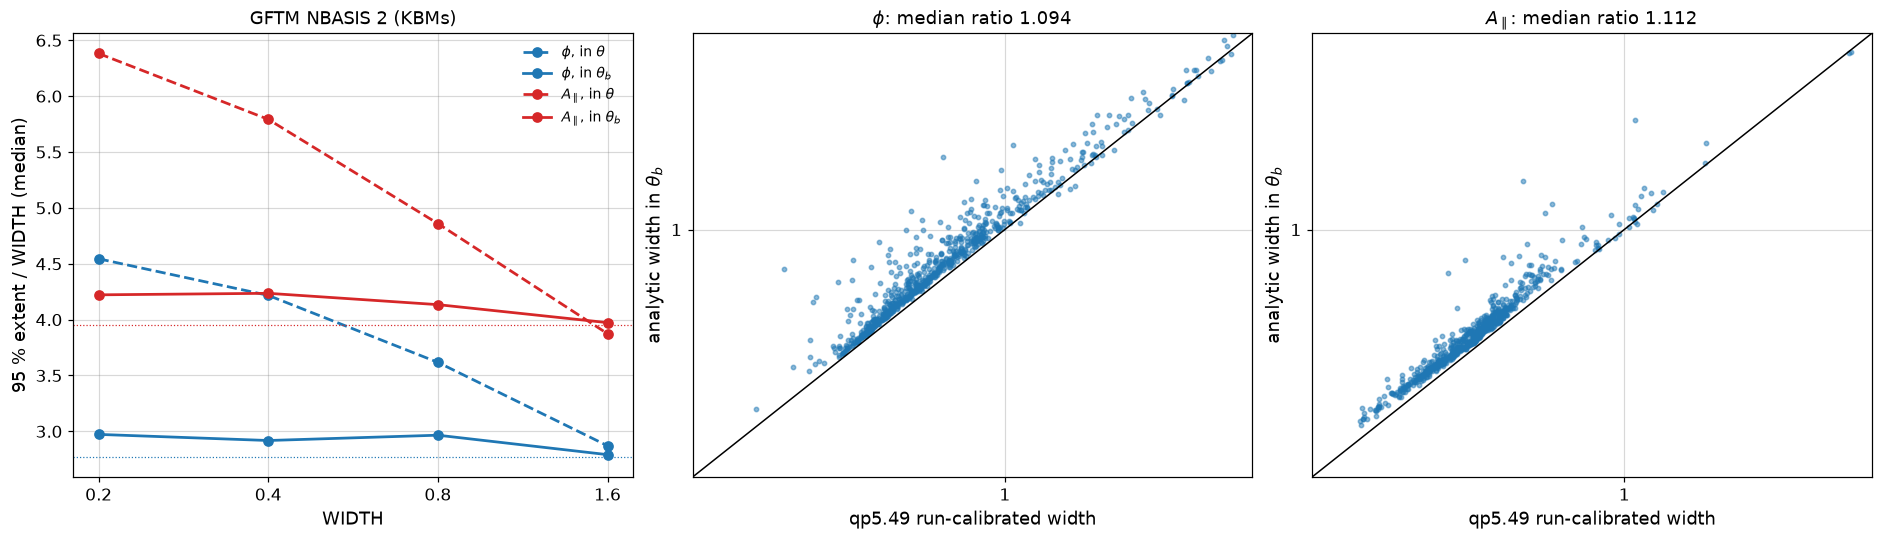

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
for field, colour in zip(fields, ("C0", "C3")):
    grouped = code_check[code_check.field == field].groupby("width")
    axes[0].plot(grouped.extent_theta_over_width.median().index, grouped.extent_theta_over_width.median(), "--o", color=colour, label=rf"{field_label[field]}, in $\theta$")
    axes[0].plot(grouped.extent_over_width.median().index, grouped.extent_over_width.median(), "-o", color=colour, label=rf"{field_label[field]}, in $\theta_b$")
    axes[0].axhline(analytic_factor[kbm_parity[field]], color=colour, lw=0.8, ls=":")
axes[0].set(xscale="log", xlabel="WIDTH", ylabel="95 % extent / WIDTH (median)", title="GFTM NBASIS 2 (KBMs)")
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:g}")); axes[0].xaxis.set_minor_locator(NullLocator()); axes[0].set_xticks(check_widths)
axes[0].legend(fontsize=9)
for ax, field in zip(axes[1:], fields):
    rows = kbm[finite[field]]
    ax.scatter(rows[f"{field}_width_calibrated"], rows[f"{field}_width_analytic"], s=8, alpha=0.5)
    limits = [0.15, 4.5]
    ax.plot(limits, limits, "k", lw=1, marker="")
    ax.set(xscale="log", yscale="log", xlim=limits, ylim=limits, xlabel="qp5.49 run-calibrated width",
           ylabel=r"analytic width in $\theta_b$", title=f"{field_label[field]}: median ratio {kbm_summary.loc[field, 'ratio_median']:.3f}")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(StrMethodFormatter("{x:g}")); axis.set_minor_locator(NullLocator())
fig.savefig(plots_dir / "gftm_extent_over_width_and_analytic_width_vs_calibrated_width.png", dpi=150); fig.savefig(plots_dir / "gftm_extent_over_width_and_analytic_width_vs_calibrated_width.pdf")
plt.show()